# Healthy–Cancer communication niches

选择 **cccphe** → **Restart Kernel and Run All**。10对独立切片（共40,000细胞），8对训练、1对验证、1对测试。联合学习共享 GNN 和 H，每张切片独立建图。只注入表达，不修改 CCC；真实区域与分组不进入模型或 K 选择。

**本次对照：**完整保留150个LR基因，另选通过训练覆盖/方差审计的预定义类型标记；背景状态没有通讯生成依据，不强行纳入编码器。新增独立训练切片的边界形态、通讯斑块方位与背景状态相位均有变化；每轮监督中心仍为8,000，原验证/测试切片完全不变。末尾提供原模型、只改输入、输入＋多样性三项比较，CCC误差统一用原训练尺度计算。

共享组织结构、免疫斑块和弯曲界面；癌症部分界面切换两个 LR 程序并叠加免疫通讯响应。局部类型/坐标在配对切片间严格匹配，表达独立抽样。两个条件均使用 Epithelial 标签，避免靠 Tumor 标签辨别疾病。

这是从既有 scCube 背景统计独立抽样的**受控通讯状态仿真**，不是完整癌症生物学；8个设计程序、6类真值不等于32维 Z，也不用于指定 K。训练只使用 CCC Huber＋正则，保留当前 NMF 初始化和20%局部 niche 聚合；不训练额外组成或疾病损失。

In [1]:
%matplotlib inline
from pathlib import Path
import sys,contextlib,json
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('retina')
from IPython.display import display
ROOT=Path('/home/xueshuailin/CCC_Phe')
sys.path.insert(0,str(ROOT/'src'))
from phenoniche.simulation.paired_tissues import PairedConfig
from scripts.compare_paired_training import main as compare_training
from phenoniche.simulation.paired_reporting import PairedReport
config=PairedConfig.from_json(ROOT/'config/healthy_cancer_communication.json')
OUTPUT=Path(config.output_dir);OUTPUT.mkdir(parents=True,exist_ok=True)
with (OUTPUT/'notebook_execution.log').open('a') as log,contextlib.redirect_stdout(log),contextlib.redirect_stderr(log):
    compare_training()
report=PairedReport(OUTPUT)
def show(fig):
    display(fig);plt.close(fig)
print(f"{report.summary['slices']} slices · {report.summary['cells']:,} cells · {report.summary['expression_genes']} encoder genes · K={report.summary['selected_K']}")

20 slices · 40,000 cells · 175 encoder genes · K=6


## 1. 未见过的健康/癌症切片：细胞类型、真实 niche 与预测

评估配色只在训练细胞上匹配；灰色表示未匹配 cluster。细胞类型图单独展示，下方2×2主图直接对比真值和预测；图例放在图外。原始 cluster ID 另存 NAS，不合并为理想真值。

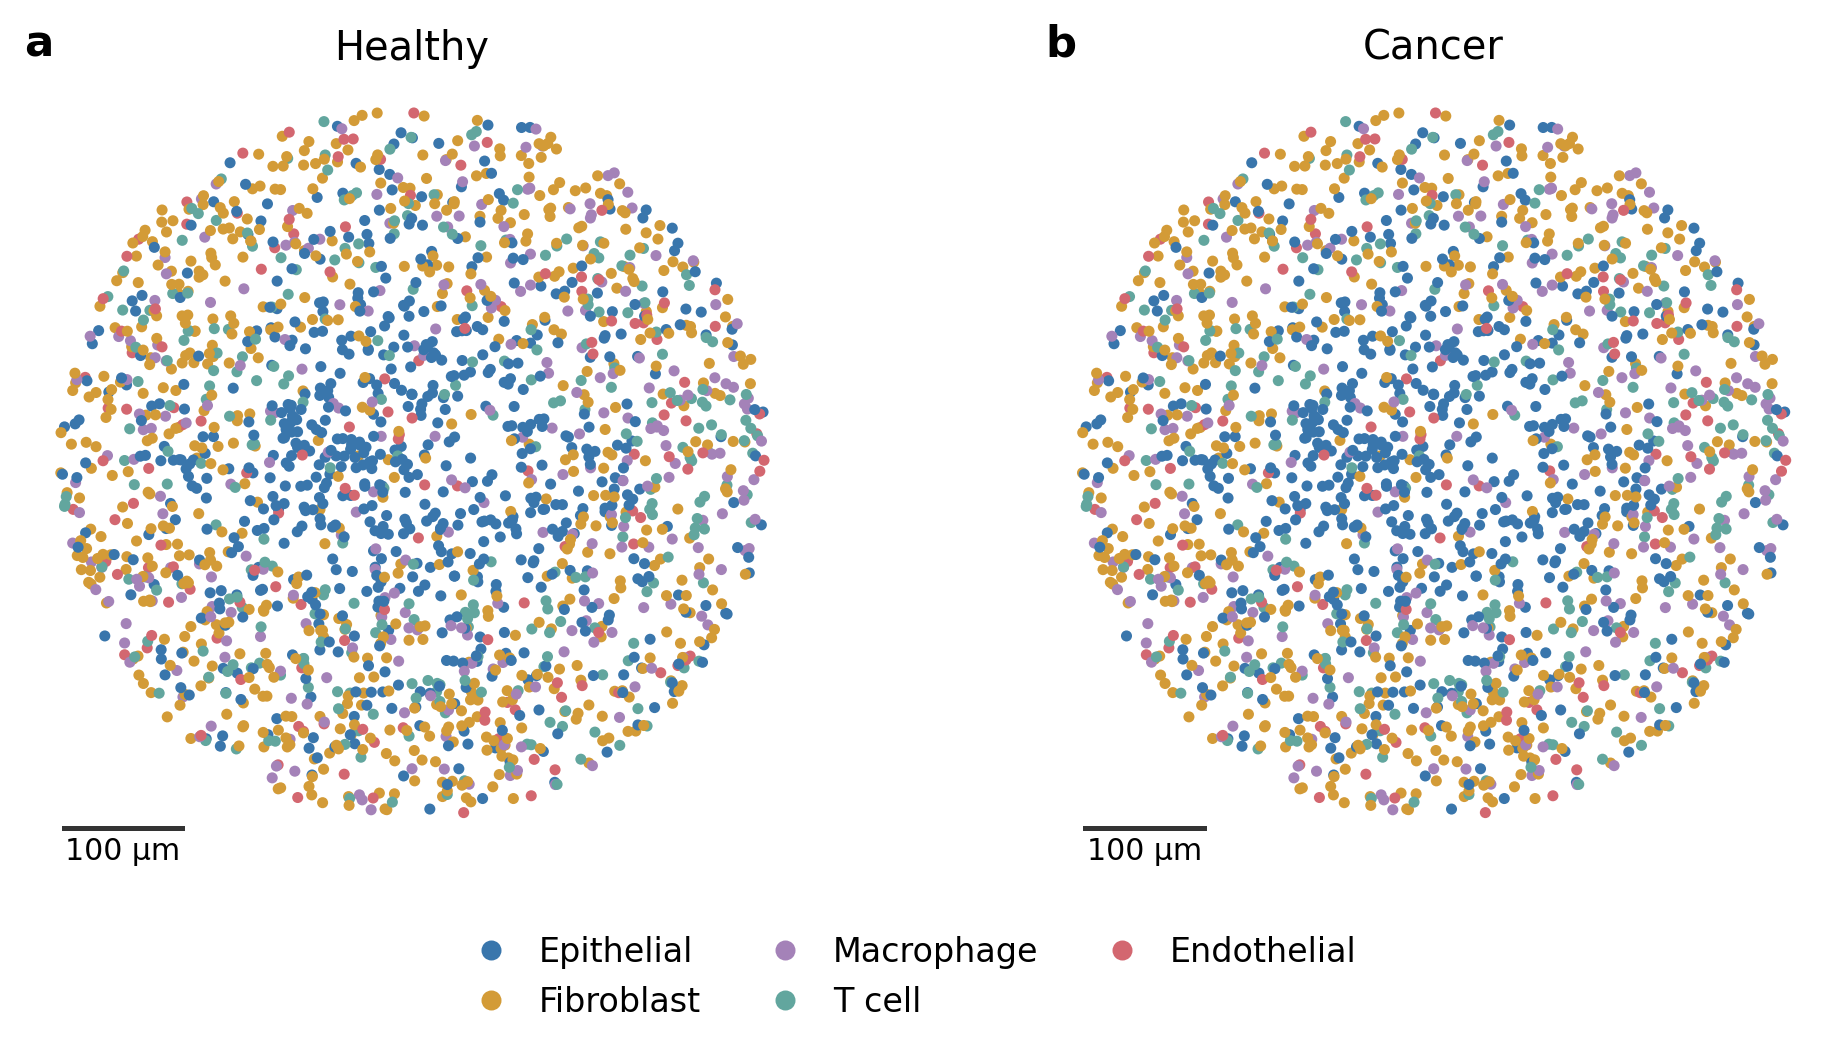

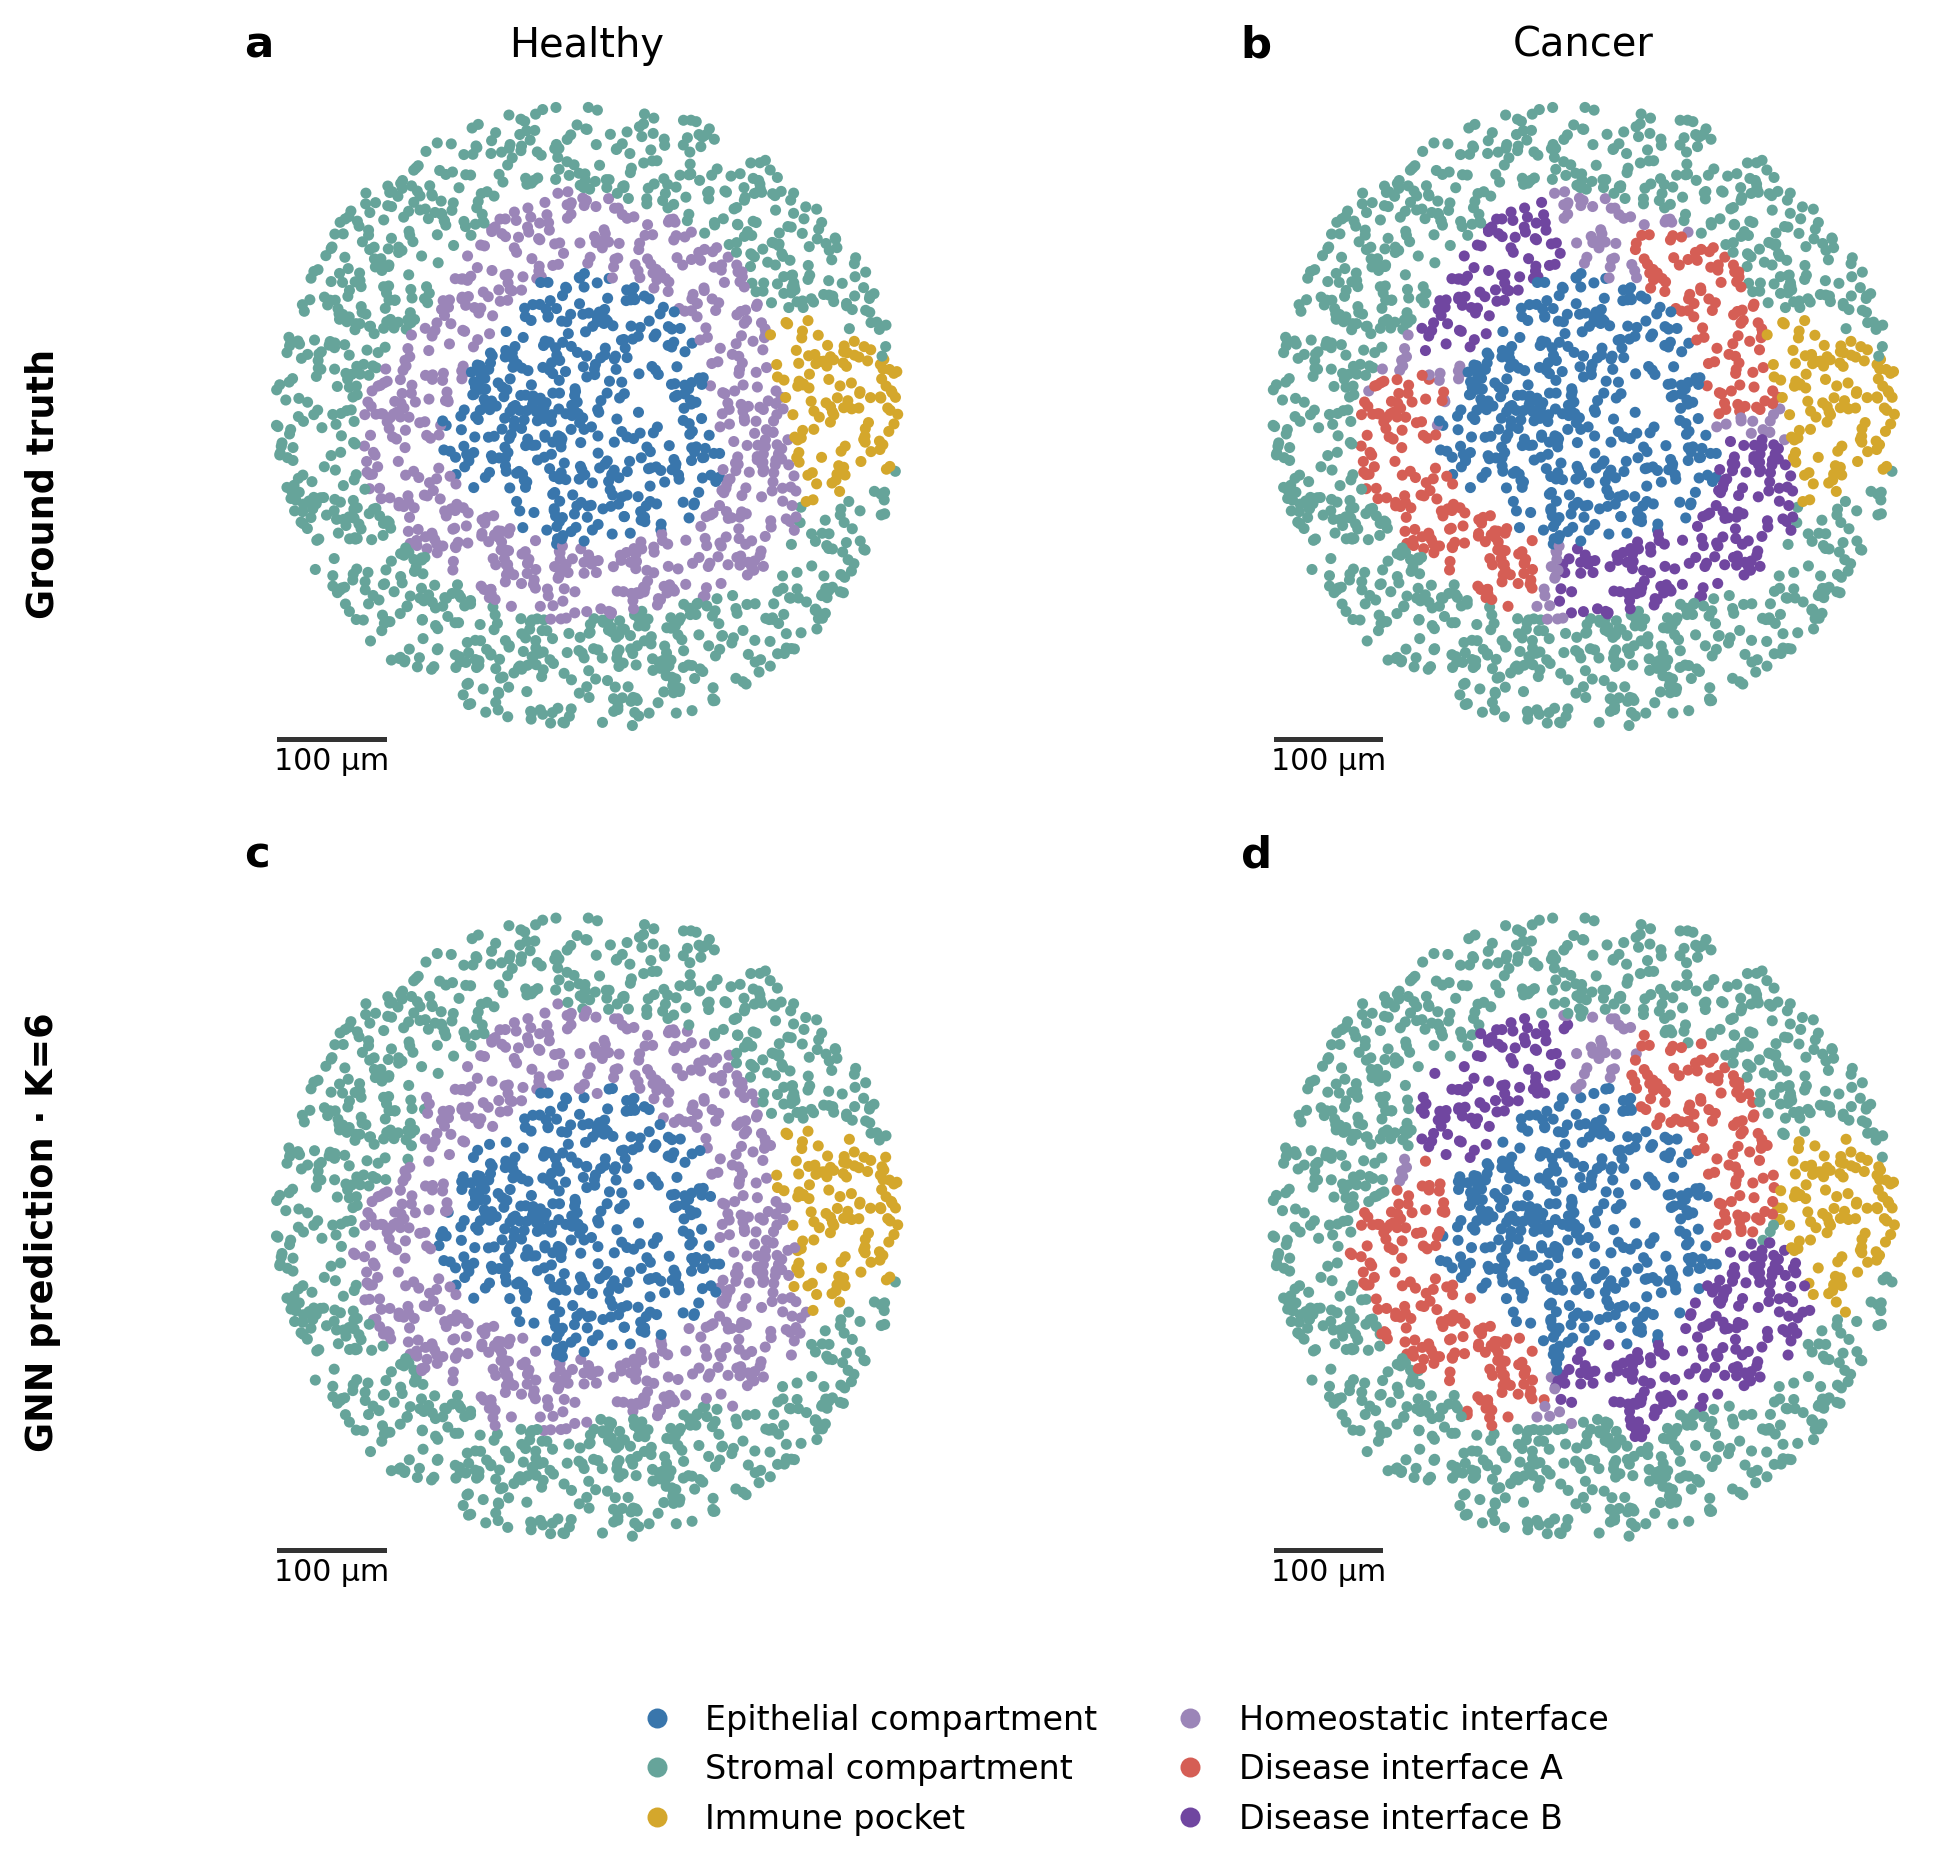

,scope,K,cells,ARI,NMI,disease_niche_F1,candidate_niches
1,heldout_slices,6,4000,0.89,0.824,0.902,2


In [2]:
show(report.cell_types())
show(report.spatial())
display(report.metrics.query("scope == 'heldout_slices'").round(3))

## 2. 哪些 niche 在患病组富集？是否只是细胞组成？

候选仅按训练切片频率定义：健康 <2%、癌症 >3%、平滑频率比 >3。配对点图中每条线连接一对切片，菱形为留出测试切片；浅色底标识训练中定义的疾病候选，不表示显著性。组成热图标注百分数。下表独立显示测试切片频率，不用测试结果筛选候选。重复数较少，不做患者级推断或伪造显著性。

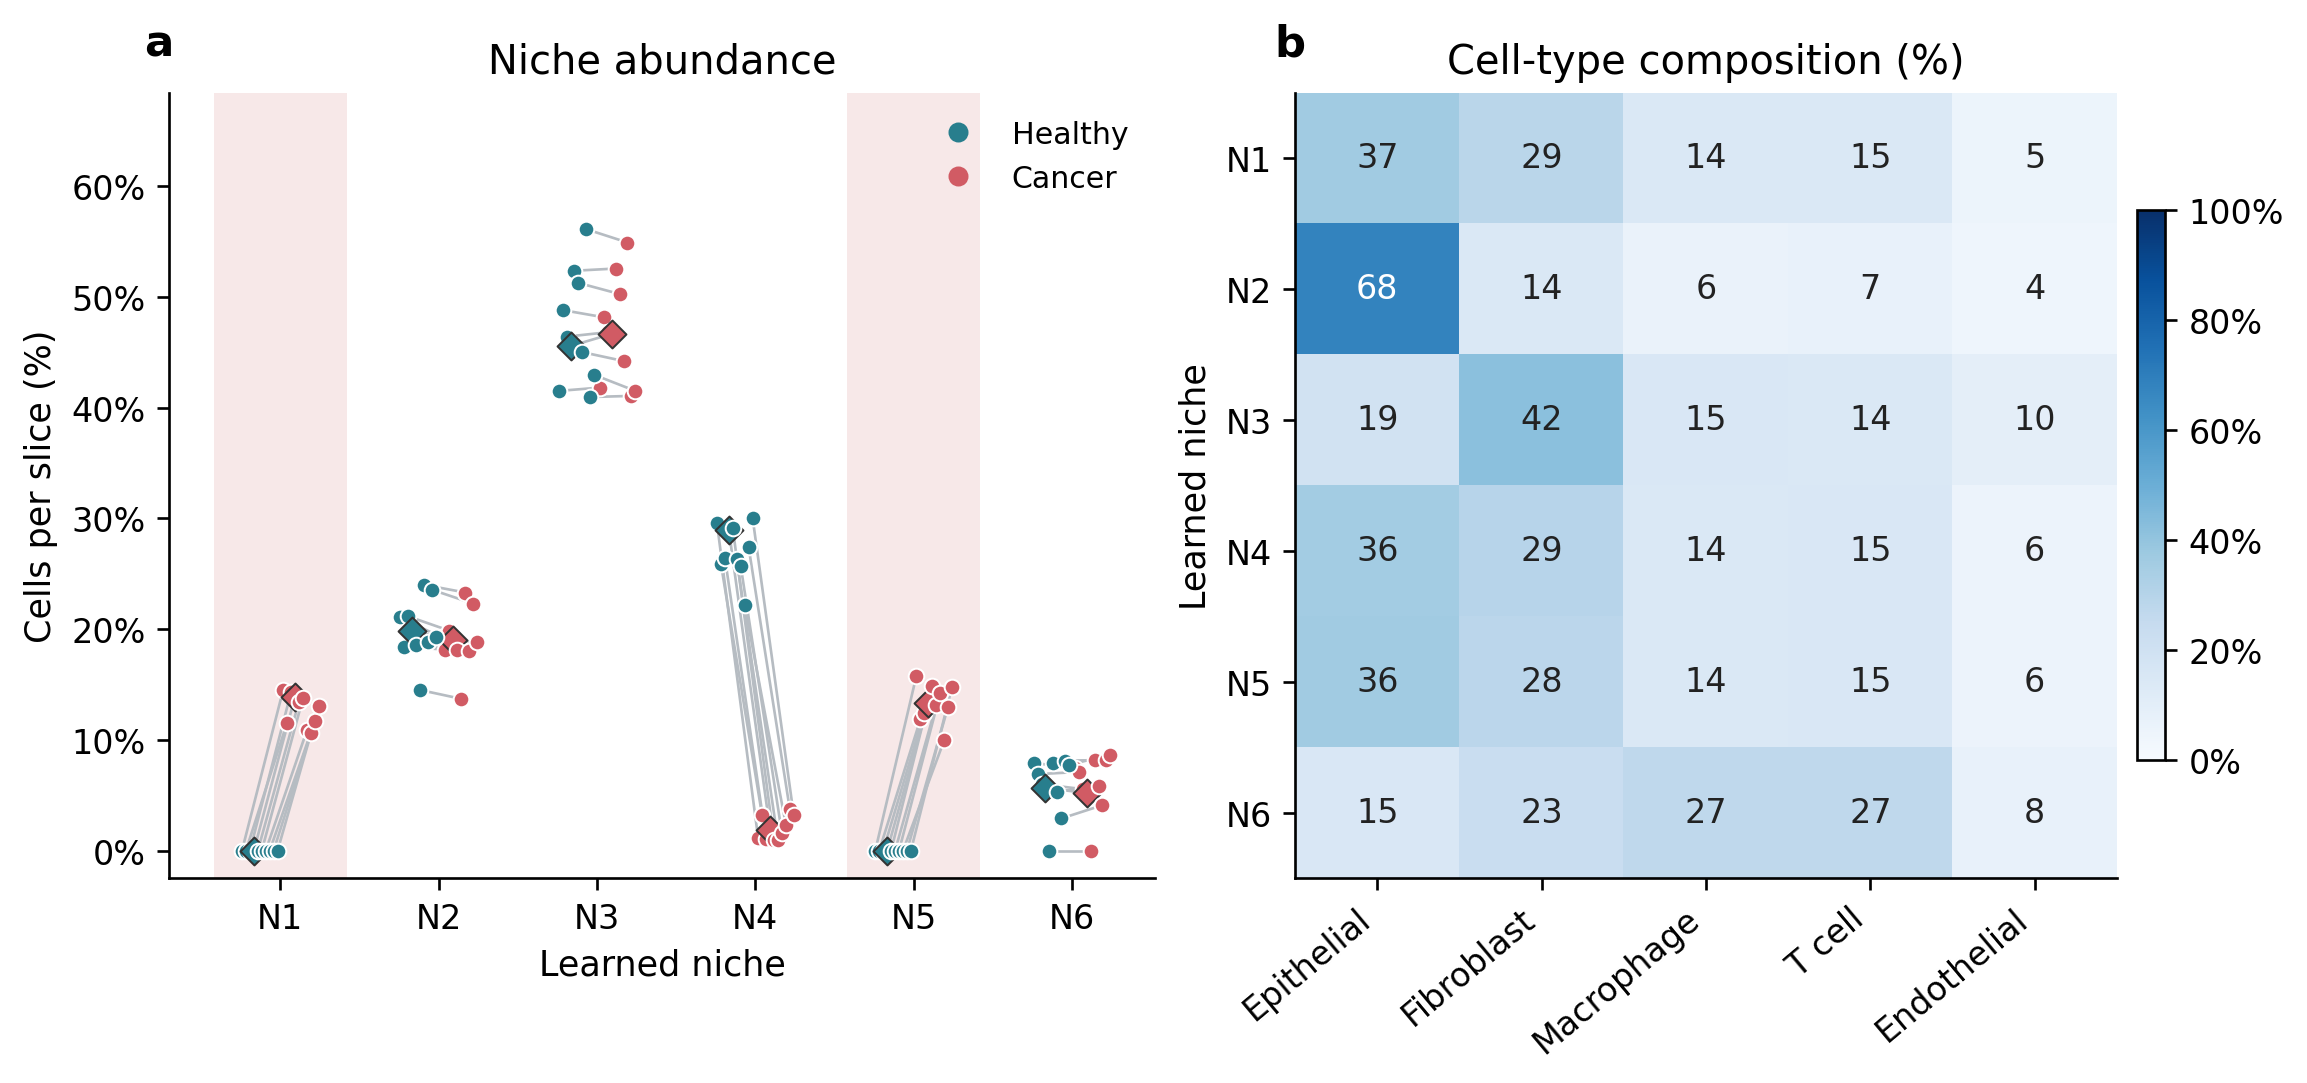

,niche,healthy_train_fraction,cancer_train_fraction,log2_enrichment,disease_specific_candidate,healthy_test_fraction,cancer_test_fraction
0,1,0.000,0.124,4.693,True,0.000,0.139
1,2,0.198,0.190,-0.059,False,0.198,0.190
2,3,0.474,0.468,-0.017,False,0.456,0.466
3,4,0.270,0.021,-3.380,False,0.290,0.019
4,5,0.000,0.135,4.803,True,0.000,0.134
5,6,0.058,0.062,0.077,False,0.056,0.052


In [3]:
show(report.groups())
display(report.enrichment.round(3))

## 3. 恢复了什么通讯程序？

真值活性按原物理细胞对和距离权重汇总。通过 H 与真实 LR loading 的相似性匹配程序，再展示未见癌症切片上的 Z；允许多个真实程序对应同一学习维度，如实展示恢复不足。每行使用统一色标；真值与Z的数值单位不同，分别标尺。ρ基于原始活性计算，完整数据未改变。

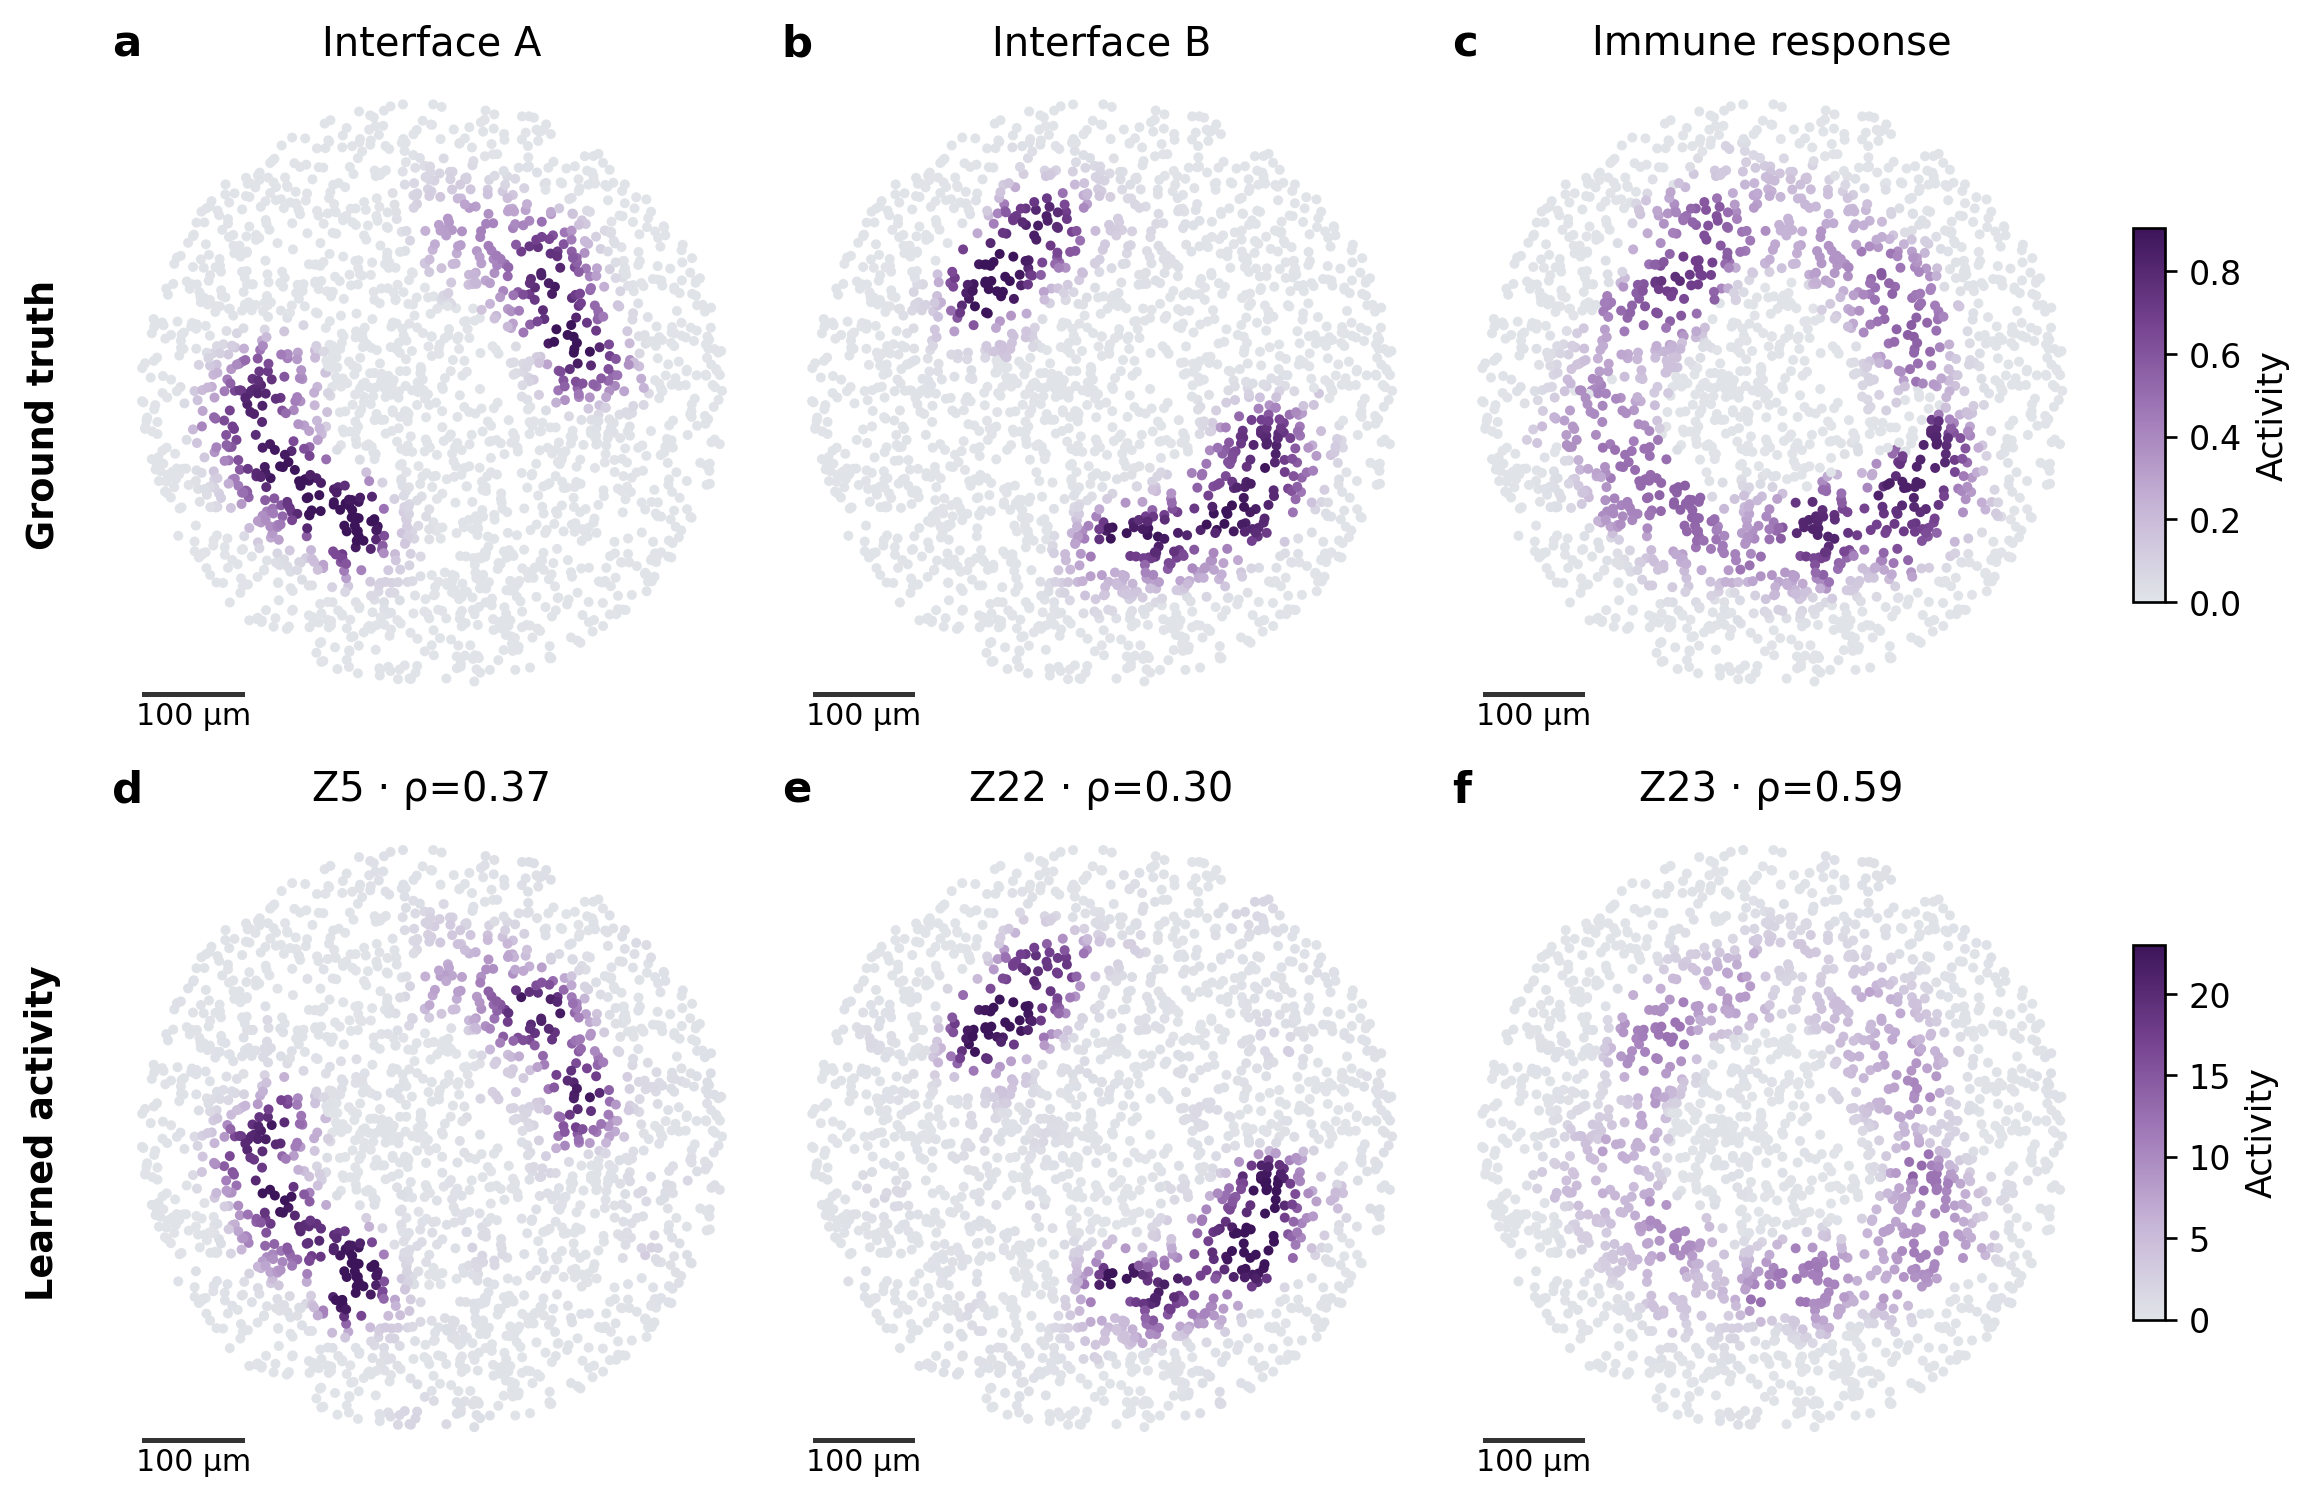

,true_program,learned_program,dictionary_cosine,heldout_activity_spearman
5,Disease interface A,5,0.993,0.371
6,Disease interface B,22,0.983,0.303
7,Disease immune response,23,0.829,0.591


,niche,rank,sender,receiver,LR,mean_reconstructed_CCC,main_program
0,1,1,Fibroblast,Epithelial,NPFF–NPFFR1,2.468,1
1,1,2,Fibroblast,Epithelial,EFNB3–EPHB6,2.441,1
2,1,3,Fibroblast,Epithelial,WNT16–FZD6,2.437,21
3,1,4,Fibroblast,Epithelial,L1CAM–ERBB2,2.427,21
4,1,5,Fibroblast,Epithelial,CNTN2–CNTN1,2.413,1
5,1,6,Fibroblast,Epithelial,SIGLEC5–SIGLEC14,2.408,1
6,1,7,Epithelial,Fibroblast,COL4A1–ITGB1,2.245,5
7,1,8,Epithelial,Fibroblast,ARTN–RET,2.175,5
8,1,9,Epithelial,Fibroblast,CCN2–NTRK1,2.149,5
9,1,10,Epithelial,Fibroblast,BCAN–NRCAM,2.131,5


In [4]:
show(report.programs())
display(report.recovery.iloc[5:].round(3))
communications=report.candidate_communications()
if len(communications):
    display(communications.round(3).head(30))
else:
    print("No niche satisfies the predeclared disease-specific criterion; inspect enrichment and recovery above.")

## 4. 训练是否正常，K 如何选择？

CCC 误差为训练集特征尺度下的 Huber 损失；竖虚点线标记实际选用的最佳 epoch。K=4–15 使用验证切片的轮廓系数、稳定性和簇规模选择，不使用分组或真实 niche。所有完整数据、矩阵、模型、原始标签及 PNG/PDF/SVG 均在 NAS。

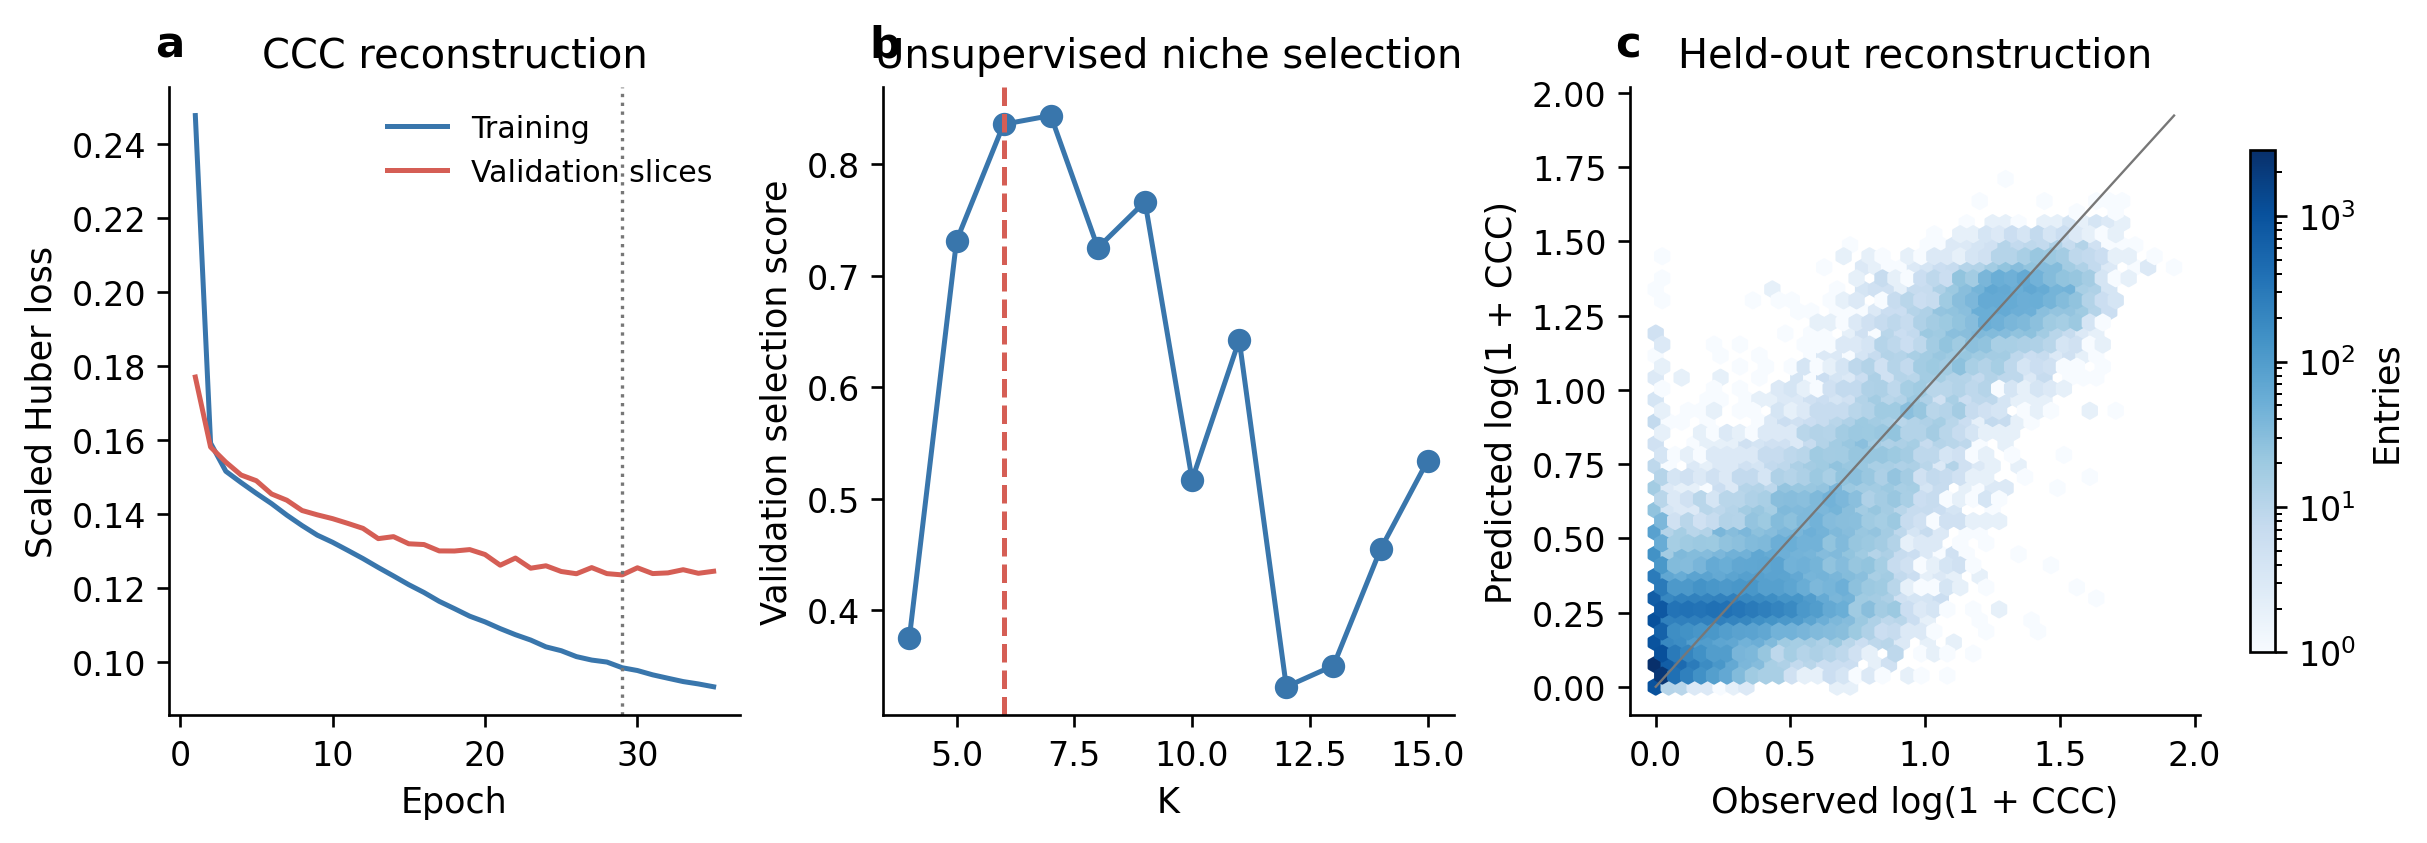

,experiment,encoder_genes,training_slices,training_centers,best_epoch,common_validation_Huber,common_test_Huber,heldout_ARI,heldout_disease_F1
0,Original all genes,3000,4,8000,5,0.182,0.189,0.796,0.878
1,LR + audited markers,175,4,8000,17,0.138,0.153,0.863,0.887
2,LR + markers; diverse slices,175,16,8000,29,0.116,0.129,0.890,0.902


Matched-composition audit passed. Results: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/healthy_cancer_diverse_training


In [5]:
show(report.training())
comparison=__import__("pandas").read_csv(OUTPUT/"experiment_comparison.csv")
display(comparison[["experiment","encoder_genes","training_slices","training_centers","best_epoch","common_validation_Huber","common_test_Huber","heldout_ARI","heldout_disease_F1"]].round(3))
audit=__import__("pandas").read_csv(OUTPUT/"pair_audit.csv")
assert audit.matched_types.all() and audit.matched_coordinates.all()
assert audit.max_weighted_composition_difference.max()<1e-6
print("Matched-composition audit passed. Results:",OUTPUT)